In [1]:
import pandas as pd
from fredapi import Fred
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ARIMA doesn't work well with financial data 

In [ ]:
API_KEY = "johndoe"

fred = Fred(api_key=API_KEY)

data = fred.get_series("M2SL", observation_start="2000-01-01")
data = data.asfreq("MS")
data = data.pct_change(fill_method=None).dropna()
print(data.head())



2000-02-01    0.002849
2000-03-01    0.006580
2000-04-01    0.011907
2000-05-01   -0.002538
2000-06-01    0.003764
Freq: MS, dtype: float64


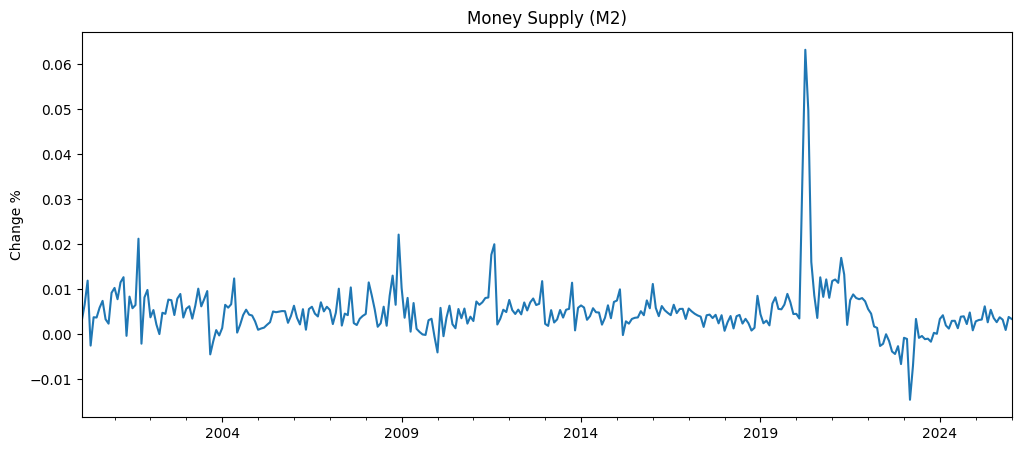

In [3]:
data.plot(figsize=(12,5), title="Money Supply (M2)")
plt.ylabel("Change %")
plt.show()

In [4]:
adf_test = adfuller(data)

print(f"ADF Statistic : {adf_test[0]:.2f}")
print(f"P-value       : {adf_test[1]:.2f}")

ADF Statistic : -4.96
P-value       : 0.00


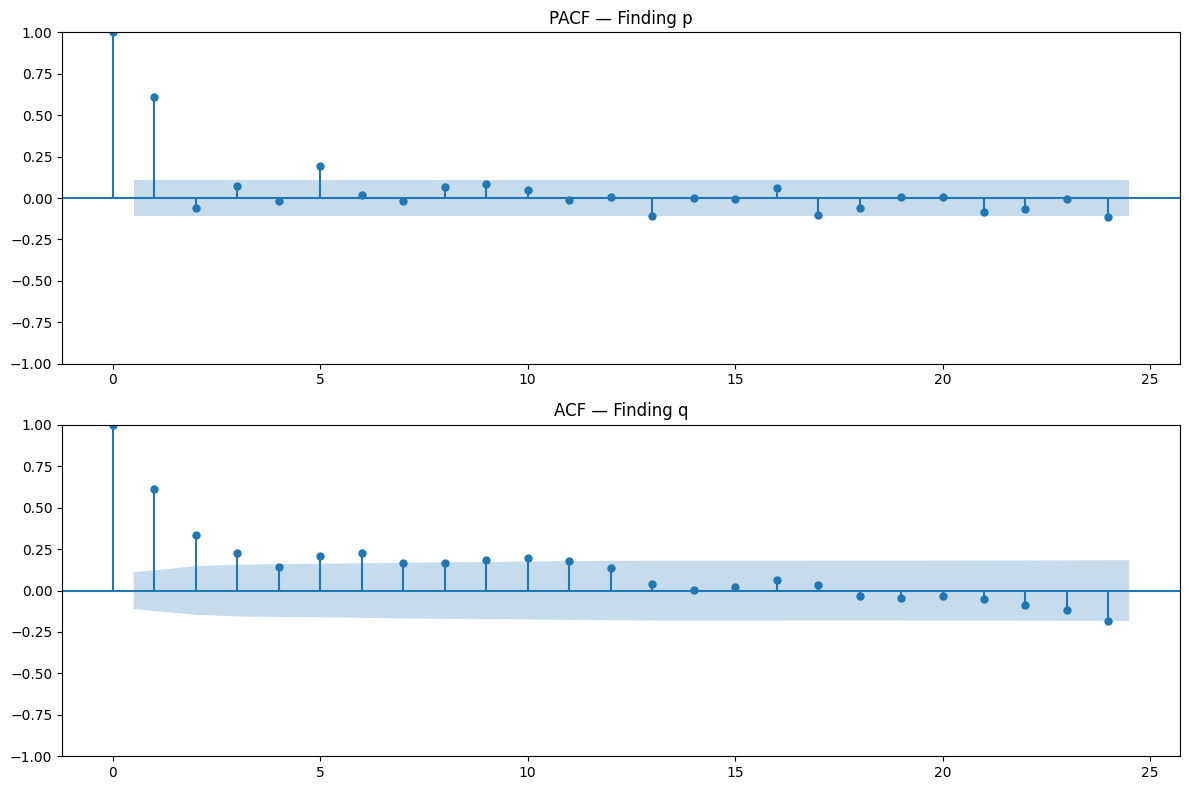

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12,8))
plot_pacf(data, lags=24, ax=ax1)
ax1.set_title("PACF — Finding p")

plot_acf(data, lags=24, ax=ax2)
ax2.set_title("ACF — Finding q")

plt.tight_layout()
plt.show()

In [6]:
model = ARIMA(data, order=(1, 0, 1))
model_fit = model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  312
Model:                 ARIMA(1, 0, 1)   Log Likelihood                1224.171
Date:                Sat, 14 Mar 2026   AIC                          -2440.341
Time:                        21:47:16   BIC                          -2425.369
Sample:                    02-01-2000   HQIC                         -2434.357
                         - 01-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0051      0.001      6.142      0.000       0.003       0.007
ar.L1          0.5463      0.044     12.525      0.000       0.461       0.632
ma.L1          0.1056      0.052      2.027      0.0

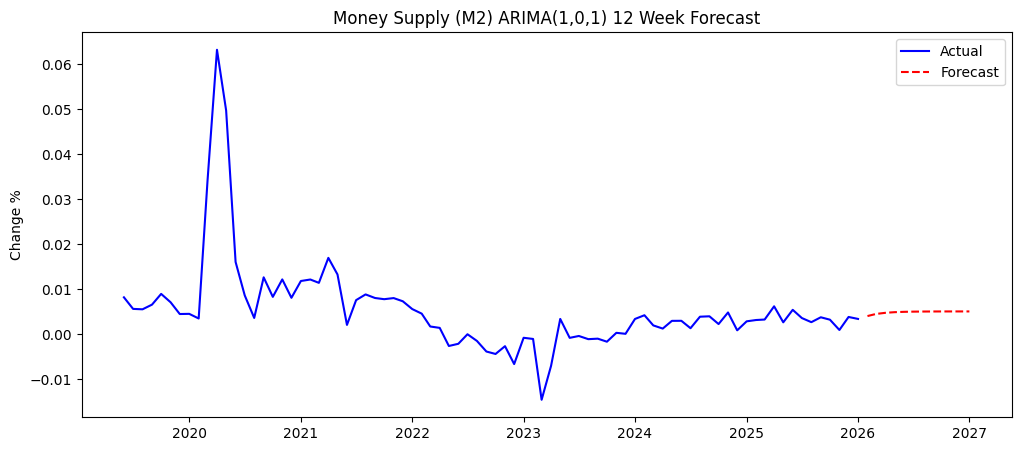

In [9]:
forecast = model_fit.forecast(steps=12)  
plt.figure(figsize=(12,5))
plt.plot(data.index[-80:], data.values[-80:], label="Actual", color="blue")
plt.plot(forecast.index, forecast.values, label="Forecast", color="red", linestyle="--")
plt.title("Money Supply (M2) ARIMA(1,0,1) 12 Week Forecast")
plt.ylabel("Change %")
plt.legend()
plt.show()